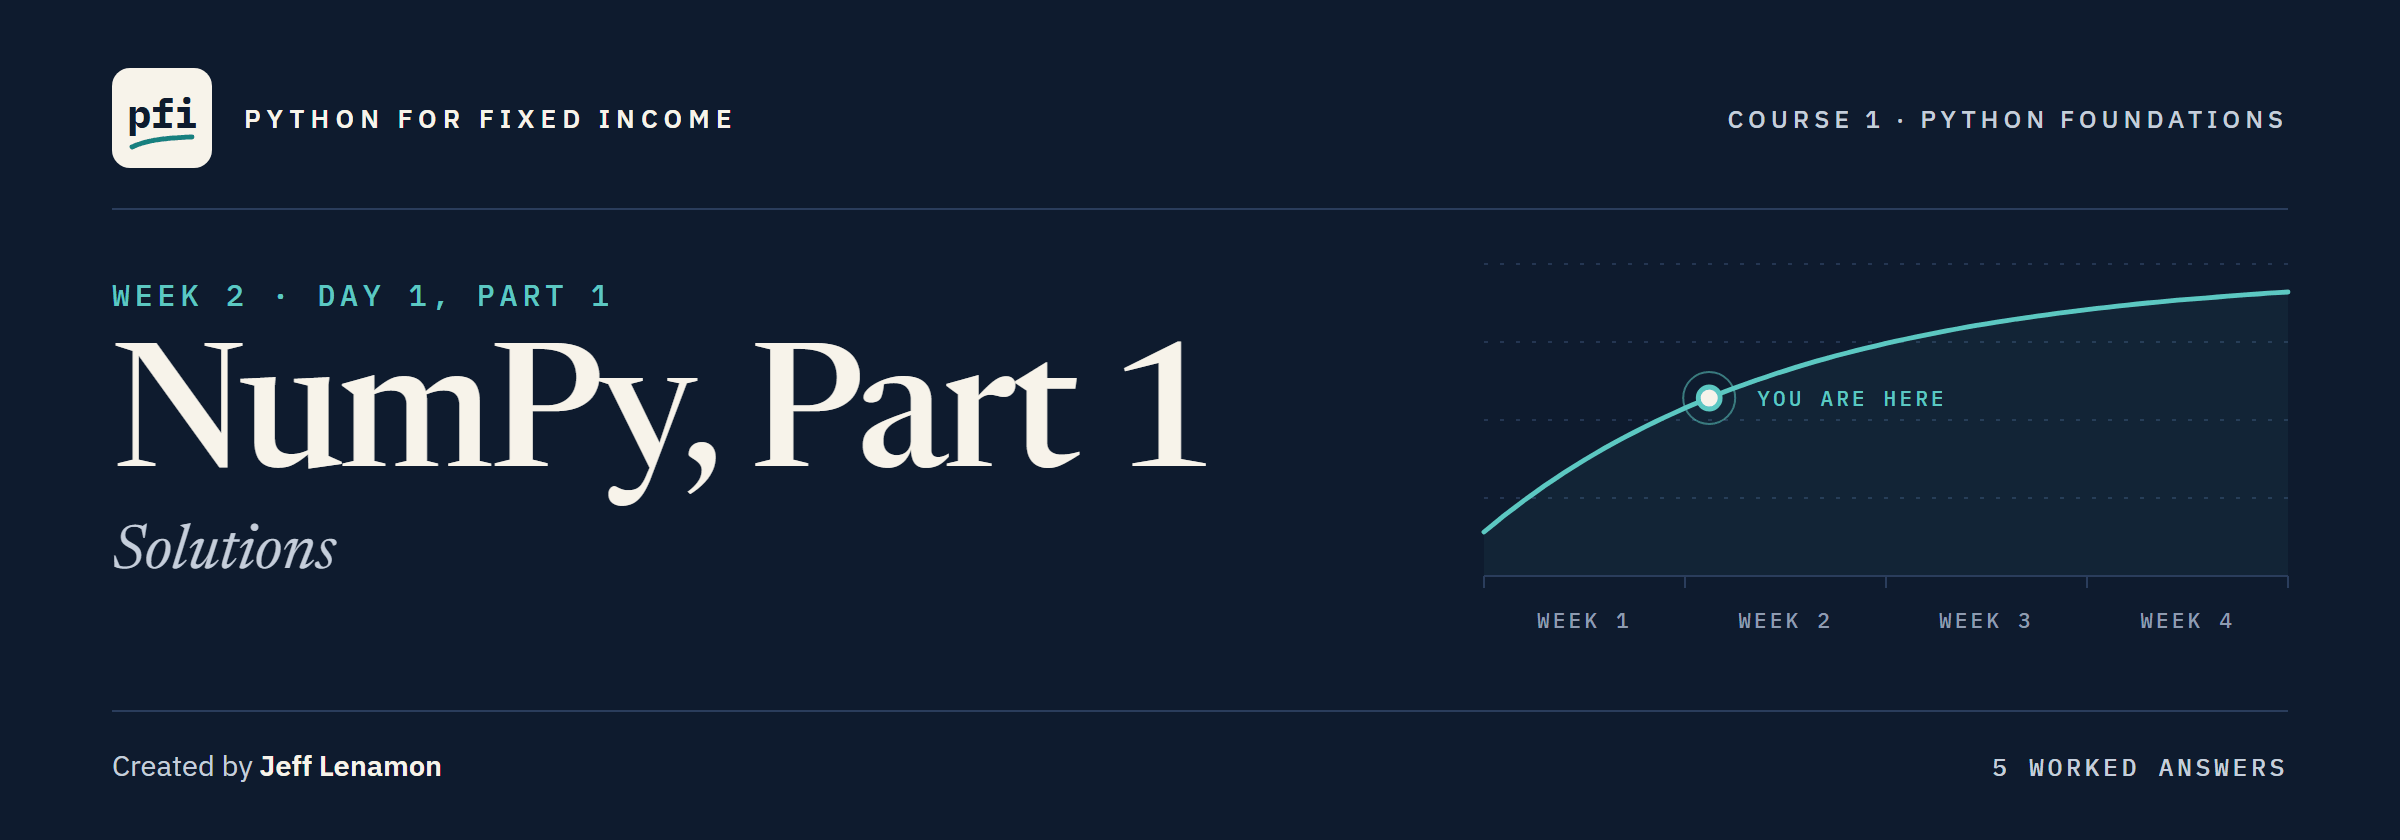

# NumPy, Part 1: Solutions

Week 2, Day 1, Part 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1/06_numpy_solutions.ipynb)

## Exercises

A second desk holds three different bonds; the issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

These are the worked answers to the exercises in the teaching notebook; each answer is followed by its check cell.
Run the next cell first: it imports NumPy and defines `check`.

In [1]:
import numpy as np


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # isinstance(x, np.ndarray) is True when x is a NumPy array;
    # its .dtype.kind is 'f' when it holds decimals
    if isinstance(expected, np.ndarray) and expected.dtype.kind == 'f':
        # arrays of numbers: same shape, and every value within a small tolerance;
        # np.shape() gives the shape of a list too
        correct = np.shape(answer) == expected.shape and np.allclose(answer, expected)
    elif isinstance(expected, np.ndarray):
        # arrays of text: np.array_equal() is True for the same shape and the same values
        correct = np.array_equal(answer, expected)
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)

### Exercise 1

Q. Create an array for the tickers, coupons, prices, and face held of the three bonds. Then work out the cost of every position in one line, and the total cost. Store the answers in **ex1_costs** and **ex1_total_cost**.

In [2]:
# one array per column, all in the same bond order
tickers = np.array(['TRNW', 'OSMC', 'CLDB'])
coupons = np.array([4.375, 5.0, 8.25])
prices = np.array([96.25, 100.0, 104.5])
faces = np.array([2000000, 1250000, 500000])

# the price is per 100 face, so divide by 100
ex1_costs = faces * prices / 100
# sum() adds up every value in the array
ex1_total_cost = ex1_costs.sum()

print('Costs:', ex1_costs)
print('Total cost:', ex1_total_cost)

Costs: [1925000. 1250000.  522500.]
Total cost: 3697500.0


1,925,000, 1,250,000, and 522,500, for a total of 3,697,500: the total this desk reached with a loop on Day 5.

In [3]:
check('Exercise 1 costs', ex1_costs, np.array([1925000.0, 1250000.0, 522500.0]))
check('Exercise 1 total cost', ex1_total_cost, 3697500.0)

Exercise 1 costs: correct
Exercise 1 total cost: correct


### Exercise 2

Q. Work out the current yield of every bond, rounded to two decimal places. Find the ticker of the bond with the highest current yield using `np.argmax()`. Then find the face-weighted average coupon. Store the answers in **ex2_current_yields**, **ex2_highest_ticker**, and **ex2_weighted_coupon**.

In [4]:
# coupon divided by price, in percent, at full precision
current_yields = coupons / prices * 100

# round at the end, for the answer that is displayed
ex2_current_yields = np.round(current_yields, 2)
print('Current yields:', ex2_current_yields)

# argmax() gives the position of the largest value, which looks up the ticker.
# It works on the unrounded yields, so rounding cannot create a tie.
ex2_highest_ticker = tickers[np.argmax(current_yields)]
print('Highest current yield:', ex2_highest_ticker)

# each coupon counts in proportion to its face
ex2_weighted_coupon = np.average(coupons, weights=faces)
print('Face-weighted average coupon:', ex2_weighted_coupon)

Current yields: [4.55 5.   7.89]
Highest current yield: CLDB
Face-weighted average coupon: 5.1


The current yields are 4.55, 5.00, and 7.89 percent, and the highest belongs to CLDB.
The face-weighted average coupon is 5.1, against a simple average of 5.875.
The weighted figure is lower because more than half of the face is in TRNW, the lowest coupon.

In [5]:
check('Exercise 2 current yields', ex2_current_yields, np.array([4.55, 5.0, 7.89]))
check('Exercise 2 highest ticker', ex2_highest_ticker, 'CLDB')
check('Exercise 2 weighted coupon', ex2_weighted_coupon, 5.1)

Exercise 2 current yields: correct
Exercise 2 highest ticker: correct
Exercise 2 weighted coupon: correct


### Exercise 3

A calculation needed again belongs in a function: next month it runs on the new holdings.

Q. Write a function `annual_income(faces, coupons)` that takes an array of face amounts and an array of annual coupons in percent, and returns the total annual coupon income as one number. The first line and the docstring are given. Replace the `...` in the body with your code, and end it with `return`.

Q. The income divided by the total face, times 100, is the face-weighted average coupon. Call your function on the three bonds, and use `np.isclose()` to test whether that figure agrees with **ex2_weighted_coupon**. Store the True or False in **ex3_agrees**.

In [6]:
def annual_income(faces, coupons):
    """
    Take an array of face amounts and an array of annual coupons in percent,
    and return the total annual coupon income as a single number.
    """
    # the income of each position, then the total
    return (faces * coupons / 100).sum()


# call the function on the three bonds
income = annual_income(faces, coupons)
print(f'Total annual coupon income: {income:,.0f}')

# income over face, in percent, against the weighted average coupon from Exercise 2
ex3_agrees = np.isclose(income / faces.sum() * 100, ex2_weighted_coupon)
print(f'Agrees with Exercise 2: {ex3_agrees}')

Total annual coupon income: 191,250
Agrees with Exercise 2: True


191,250 of coupon a year on 3,750,000 of face is 5.1 percent, the face-weighted average coupon from Exercise 2, so the test is True.
The function ends with `return`, so the total comes back as a value that can be stored, divided, and compared; a function that only printed it would hand back `None`.
The check cell calls the function on arrays of its own: a function is checked by calling it.

In [7]:
# the check calls your function on the three bonds
check('Exercise 3 income', annual_income(np.array([2000000, 1250000, 500000]),
                                         np.array([4.375, 5.0, 8.25])), 191250.0)
check('Exercise 3 agrees', ex3_agrees, True)

Exercise 3 income: correct
Exercise 3 agrees: correct


### Exercise 4

CLDB closed at 104.50, 104.00, 104.25, and 105.00 on four days.

Q. Put the four closes in an array. Find the simple return on each of the three days, as a decimal, and store the three returns in **ex4_simple_returns**. Find the sum of the daily log returns and store it in **ex4_log_total**. Then find the sample standard deviation of the four closes and store it in **ex4_sample_std**.

In [8]:
cldb_week = np.array([104.5, 104.0, 104.25, 105.0])

# each change over the price the day before
ex4_simple_returns = np.diff(cldb_week) / cldb_week[:-1]
print('Simple returns:', np.round(ex4_simple_returns, 6))

# today over yesterday, then the log, then the total
ex4_log_total = np.log(cldb_week[1:] / cldb_week[:-1]).sum()
print('Sum of the log returns:', round(ex4_log_total, 6))

# ddof=1 divides by the count minus 1, as STDEV.S does in Excel
ex4_sample_std = np.std(cldb_week, ddof=1)
print('Sample standard deviation:', round(ex4_sample_std, 6))

Simple returns: [-0.004785  0.002404  0.007194]
Sum of the log returns: 0.004773
Sample standard deviation: 0.426956


The three simple returns are about -0.48, 0.24, and 0.72 percent.
The log returns add up to about 0.477 percent, the log of 105 over 104.5: the move over the whole four days.
The sample standard deviation of the four closes is about 0.427 points.

In [9]:
check('Exercise 4 simple returns', ex4_simple_returns,
      np.array([-0.00478469, 0.00240385, 0.00719424]))
check('Exercise 4 log total', ex4_log_total, 0.00477328)
check('Exercise 4 sample standard deviation', ex4_sample_std, 0.42695628)

Exercise 4 simple returns: correct
Exercise 4 log total: correct
Exercise 4 sample standard deviation: correct


### Exercise 5: AI check

You ask an AI assistant for code that gives the weighted average coupon of the three positions; it has one bug.

Q. Read the code before you run it: you worked out the face-weighted average coupon in Exercise 2. Then run it. Does it agree with you?

The answer from Exercise 2 is 5.1; the original code printed 5.93, with no error.
The bug was in the weights: `weights=ai_prices` weighted each coupon by the bond's price, and three prices near 100 make that nearly a simple average.
The weights have to be the face held: `weights=ai_faces`.
The result looked like a coupon and sat inside the range of the three coupons, so nothing stood out; the check that caught it was a number worked out independently.

In [10]:
ai_coupons = np.array([4.375, 5.0, 8.25])
ai_prices = np.array([96.25, 100.0, 104.5])
ai_faces = np.array([2000000, 1250000, 500000])

# weight each coupon by the face held, not by the price
ex5_weighted_coupon = np.average(ai_coupons, weights=ai_faces)
print(f'The weighted average coupon is {round(ex5_weighted_coupon, 2)} percent')

The weighted average coupon is 5.1 percent


In [11]:
check('Exercise 5', ex5_weighted_coupon, 5.1)

Exercise 5: correct


[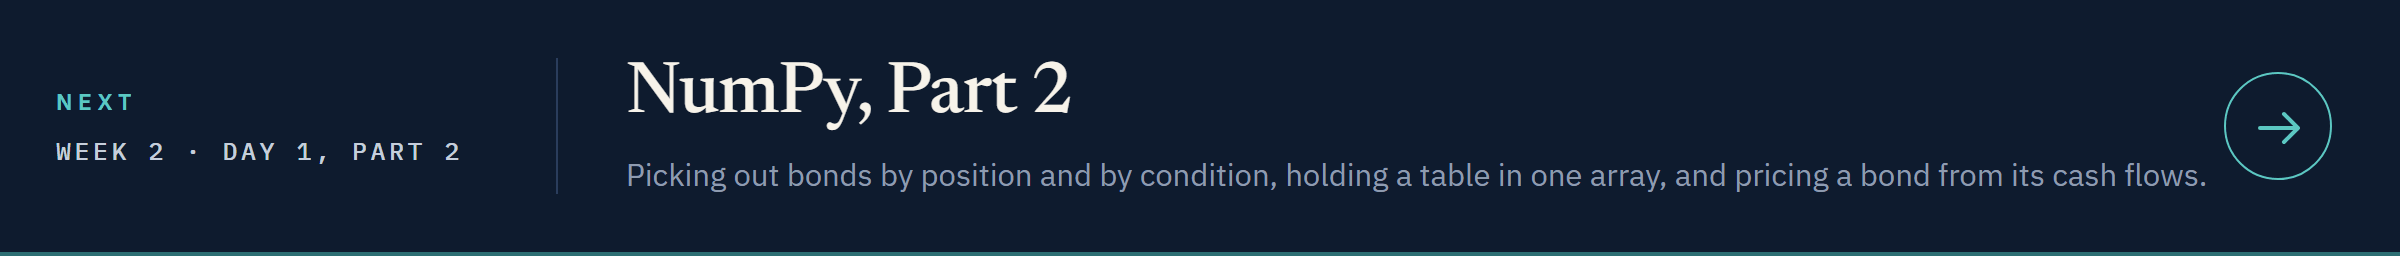](../day1_part2/06_part2_numpy.ipynb)

[Open Day 1, Part 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1_part2/06_part2_numpy.ipynb)